In [11]:
import os
# Must be set before numpy is imported: single-threaded BLAS is faster for n=128
# and lets the parallel workers below not fight over cores.
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "figure.dpi":300,
})

folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent
sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator

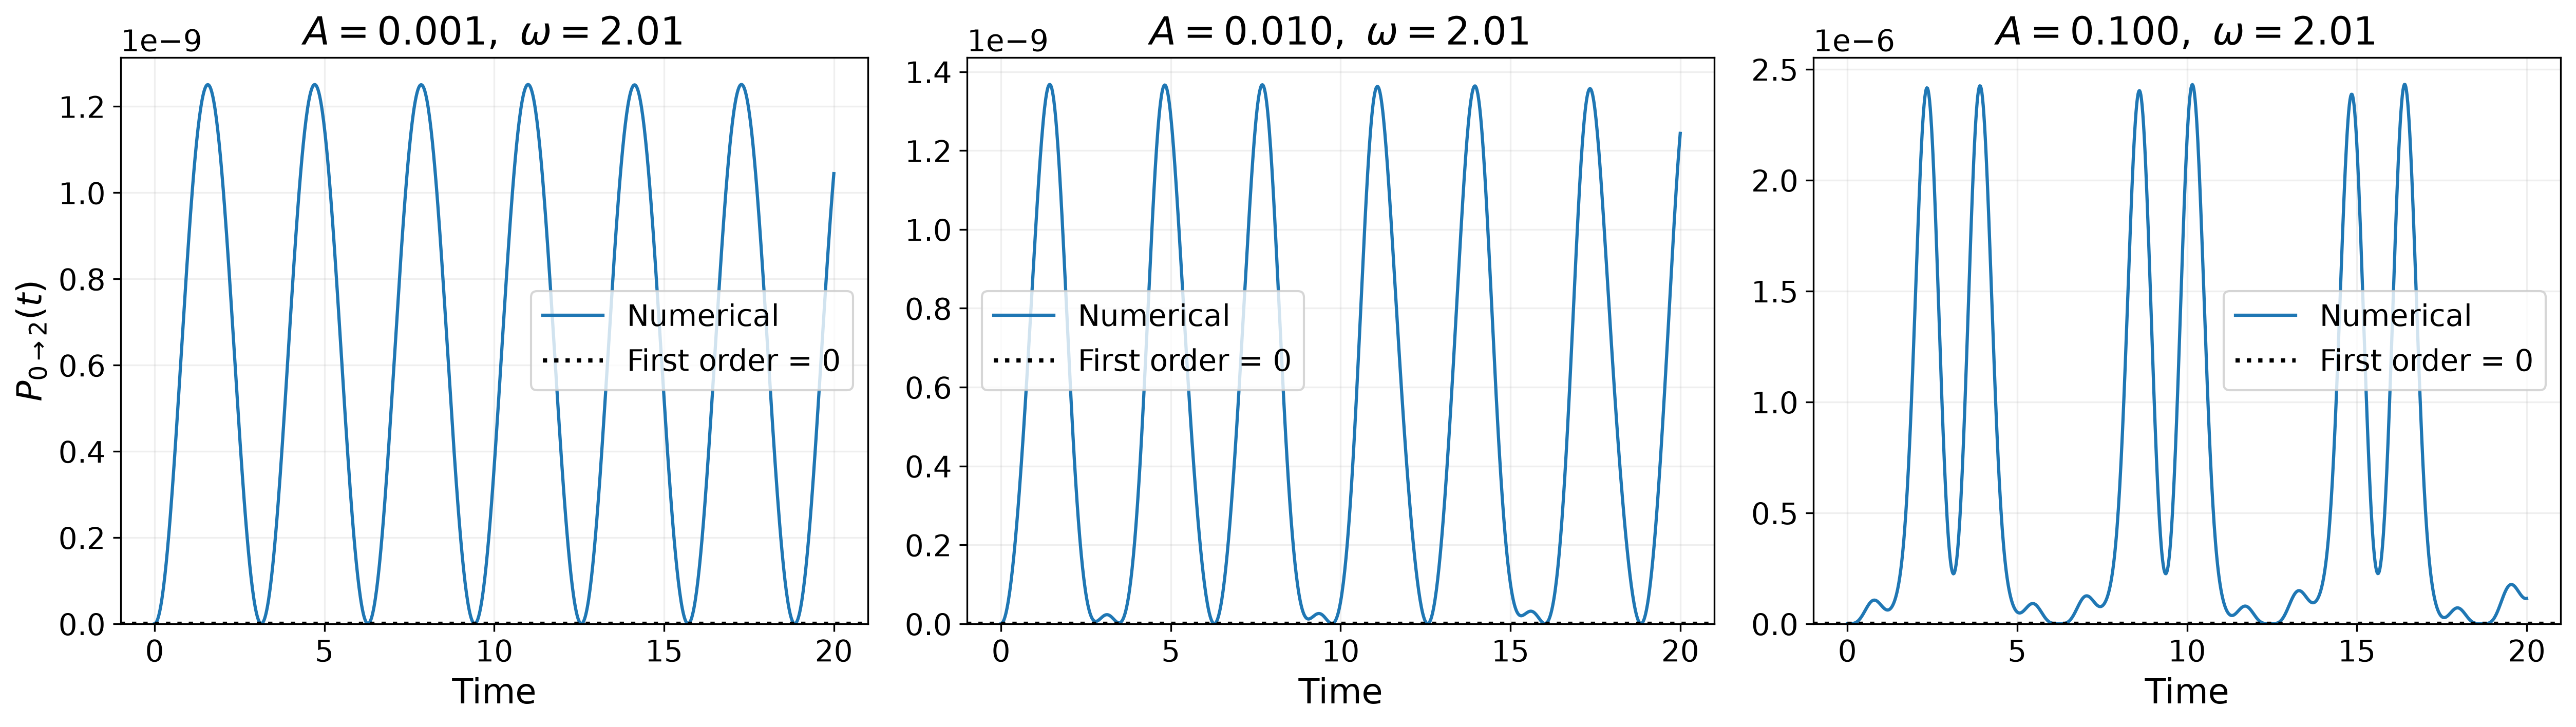

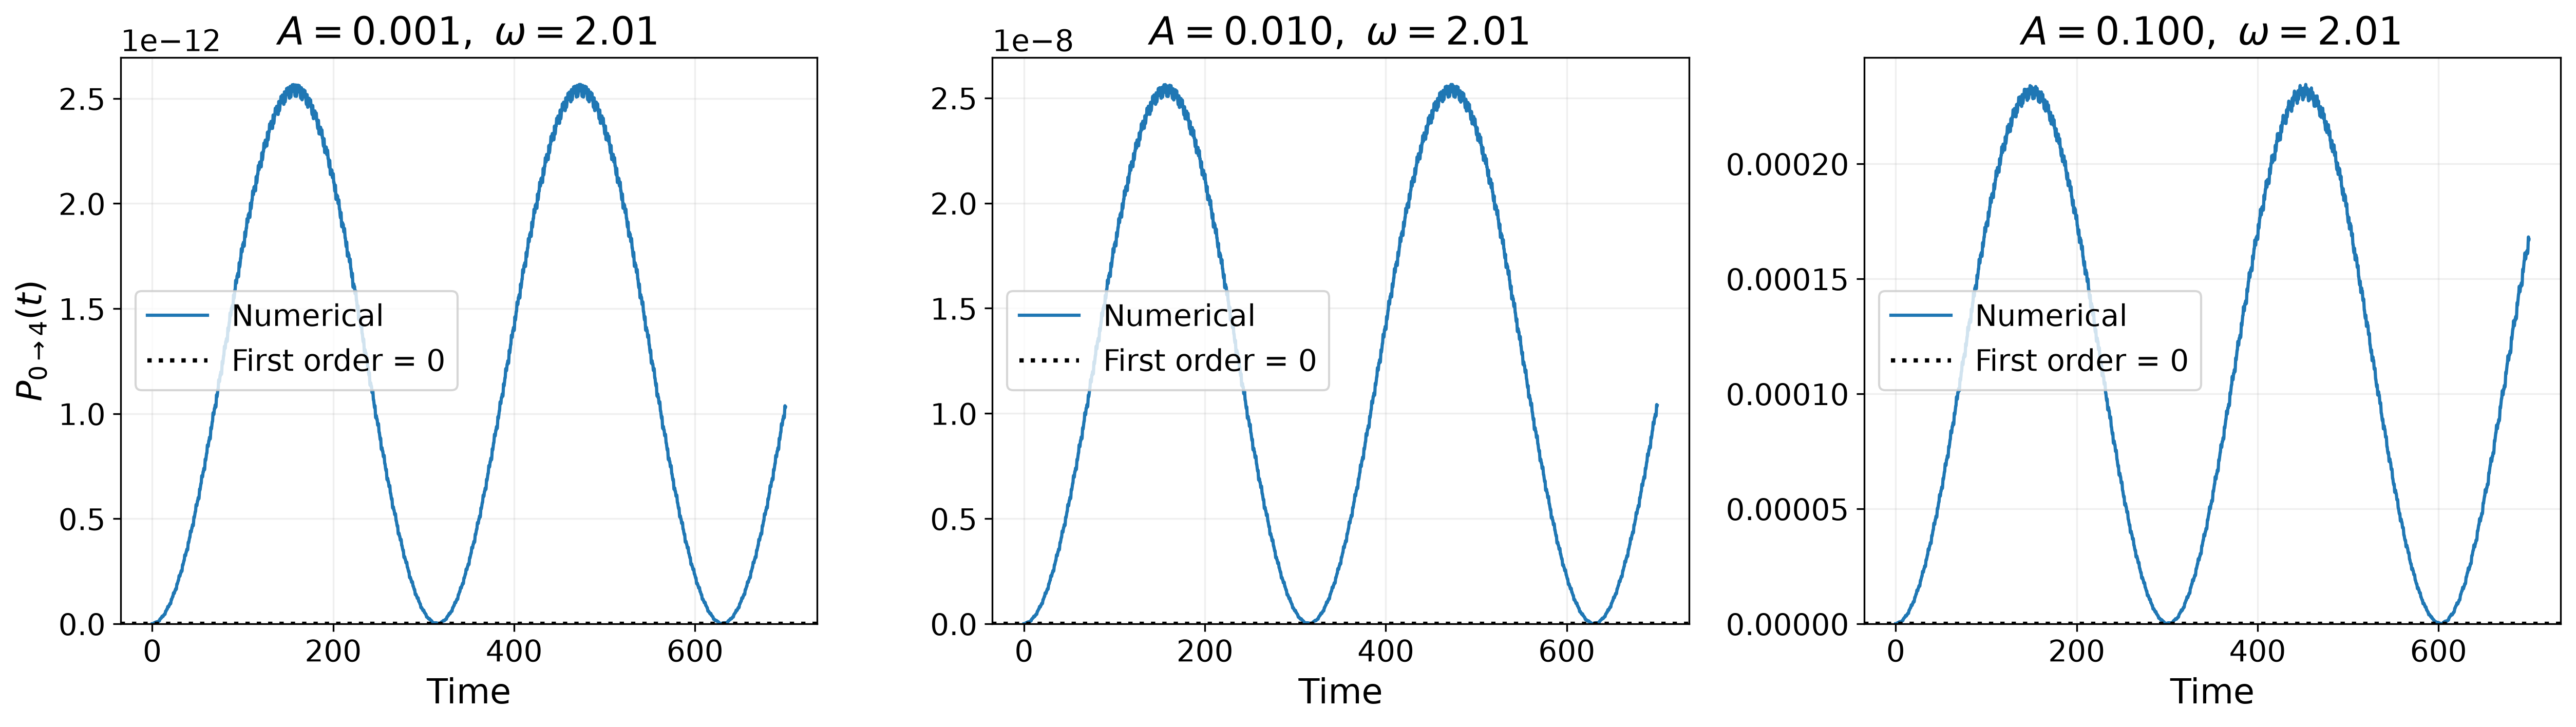

In [12]:
from concurrent.futures import ProcessPoolExecutor
# populations() lives in simulation.py so parallel workers can import it (needed on Windows)
from simulation import populations

# Parameters
omega = 2.01
A_values = [0.001, 0.01, 0.1]
n = 128
L = 12
levels = [2, 4]

tmax_upper = 20
tmax_lower = 700

# One run per A to tmax_lower; the upper figure plots only its first tmax_upper
with ProcessPoolExecutor() as pool:
    futures = {A: pool.submit(populations, A, omega, tmax_lower, levels, n=n, L=L) for A in A_values}
    results = {A: f.result() for A, f in futures.items()}

# Upper figure: second excited state, lower figure: fourth excited state
for k, (level, tmax_plot) in enumerate([(2, tmax_upper), (4, tmax_lower)]):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    for ax, A in zip(axes, A_values):
        t, P = results[A]
        keep = t <= tmax_plot

        ax.plot(t[keep], P[keep, k], label="Numerical")
        ax.axhline(
            0, color="black", linestyle=":", linewidth=2,
            label="First order = 0"
        )

        ax.set_title(rf"$A={A:.3f},\ \omega={omega:.2f}$")
        ax.set_xlabel("Time")
        ax.set_ylim(bottom=0)
        ax.legend()
        ax.grid(alpha=0.2)
    axes[0].set_ylabel(rf"$P_{{0\to{level}}}(t)$")
    fig.tight_layout()

plt.show()

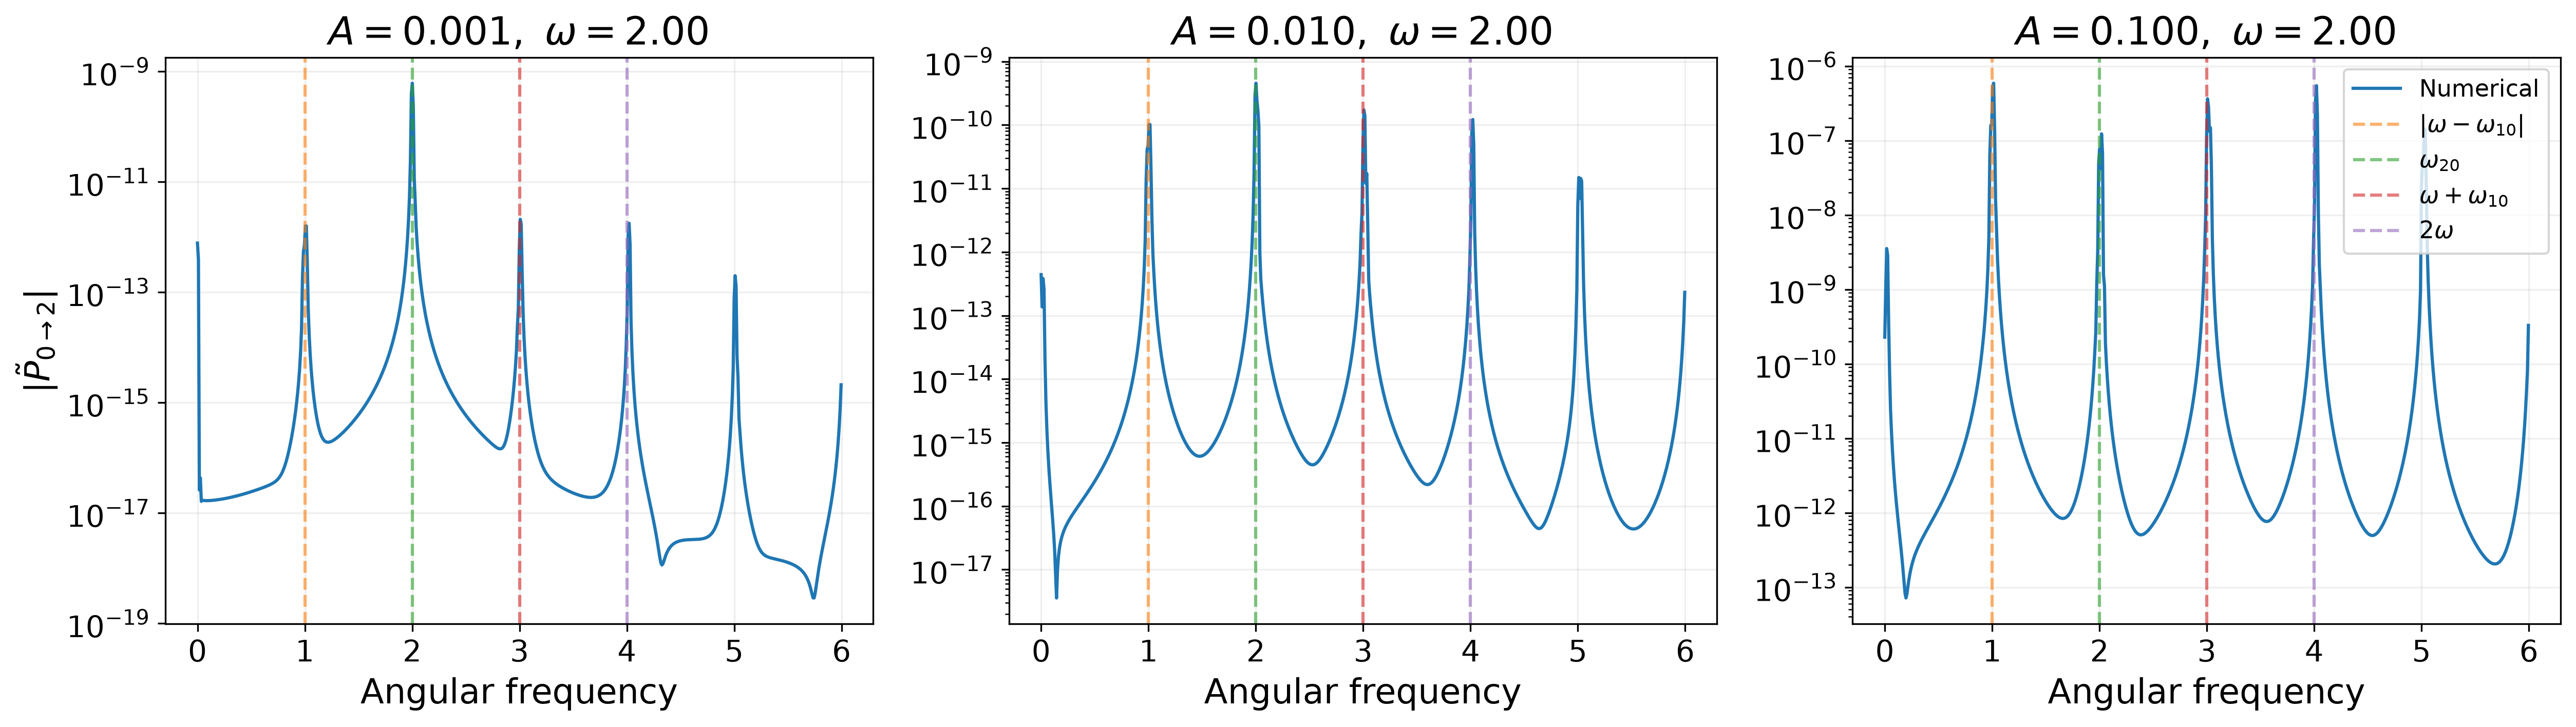

In [ ]:
# Fourier transform of P_{0->2}(t), reusing the runs above
# Predicted lines: |omega - omega_10|, omega_20 (split-step dt artifact), omega + omega_10, 2*omega
lines = {
    r"$|\omega-\omega_{10}|$": abs(omega - 1),
    r"$\omega_{20}$": 2.0,
    r"$\omega+\omega_{10}$": omega + 1,
    r"$2\omega$": 2 * omega,
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, A in zip(axes, A_values):
    t, P = results[A]
    P2 = P[:, levels.index(2)]

    window = np.hanning(len(t))  # reduces spectral leakage from the finite time window
    spectrum = np.abs(np.fft.rfft((P2 - P2.mean()) * window)) * 2 / window.sum()
    freq = 2 * np.pi * np.fft.rfftfreq(len(t), t[1] - t[0])  # angular frequency

    keep = freq <= 6
    ax.semilogy(freq[keep], spectrum[keep], label="Numerical")
    for (name, w), color in zip(lines.items(), ["C1", "C2", "C3", "C4"]):
        ax.axvline(w, color=color, linestyle="--", alpha=0.6, label=name)

    ax.set_title(rf"$A={A:.3f},\ \omega={omega:.2f}$")
    ax.set_xlabel(r"Angular frequency")
    ax.grid(alpha=0.2)
axes[0].set_ylabel(r"$|\tilde{P}_{0\to2}|$")
axes[-1].legend(fontsize=11, loc="upper right")
fig.tight_layout()

plt.show()

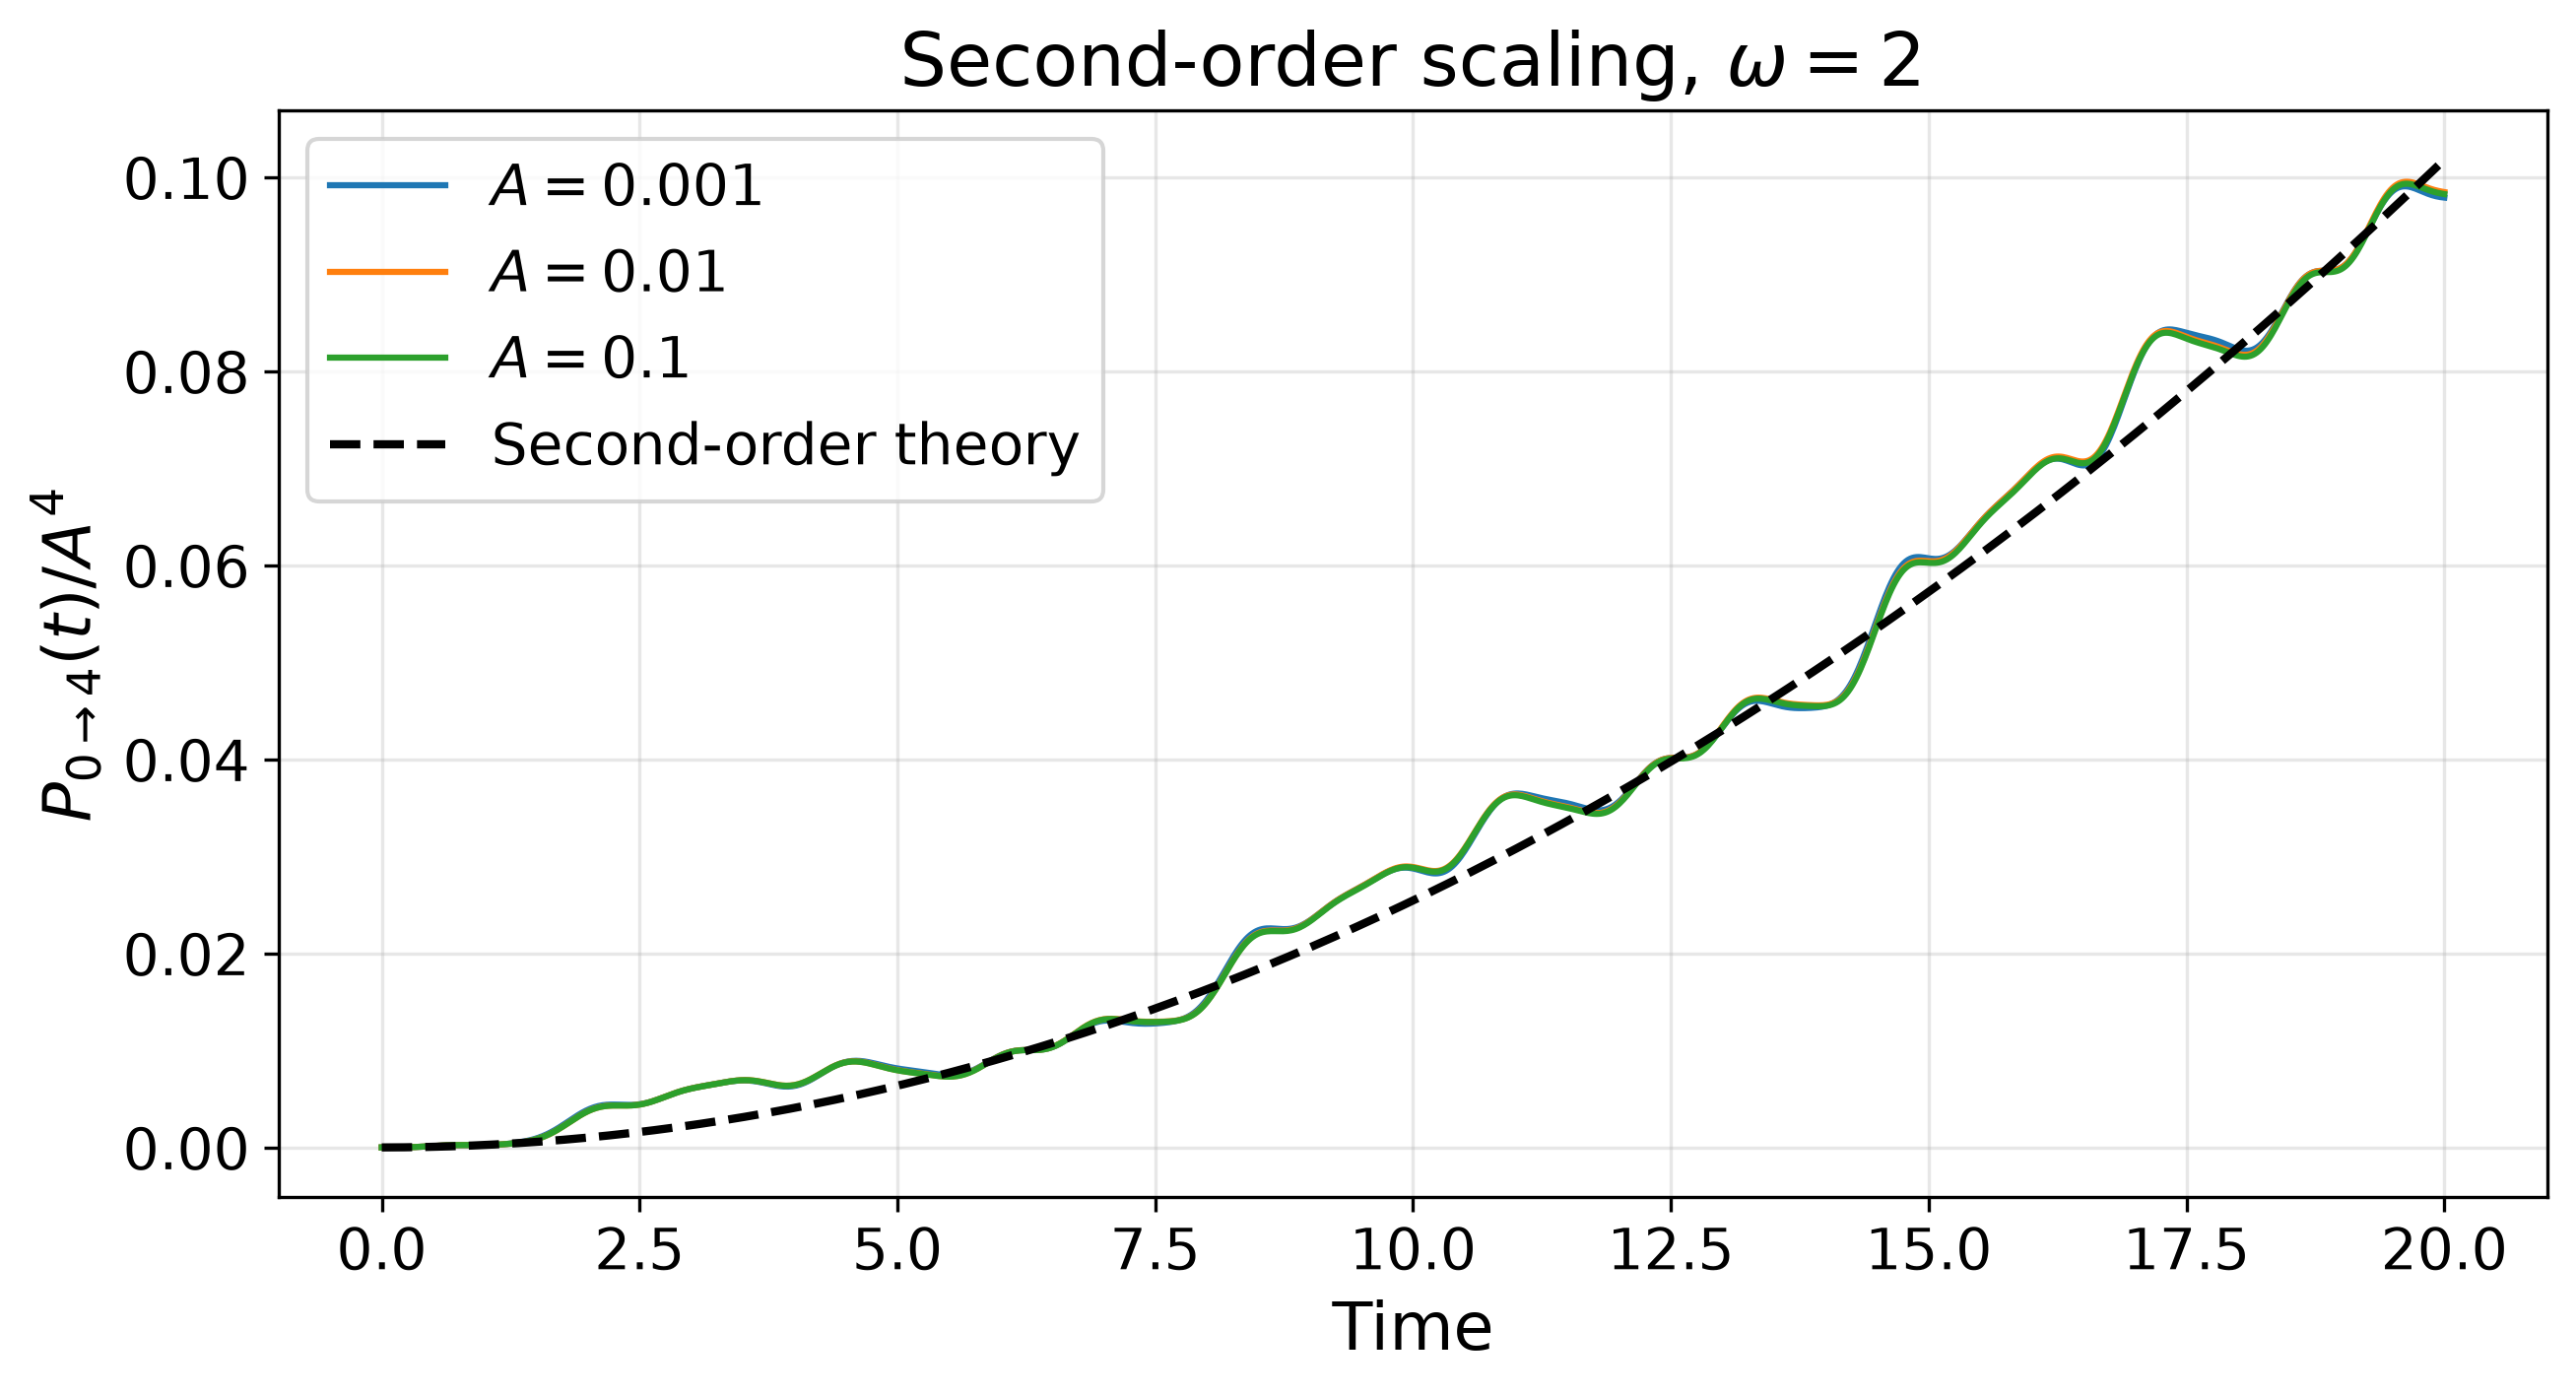

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

A_values = [0.001, 0.01, 0.1]
omega = 2.0
tmax = 20

ho = HarmonicOscillator(boundary=(-L, L), n=n)
energies, basis = ho.eigenstates()
phi4 = basis[:, 4]

plt.figure(figsize=(9, 5))

def simulate(A=0.05, omega=1.0, dt=0.02, n=128, L=12, tmax=20, t_eval=None):
    ho = HarmonicOscillator(boundary=(-L, L), n=n)
    x = ho.xi()
    times = np.linspace(0, tmax, int(np.ceil(tmax / dt)) + 1)

    energies, basis = ho.eigenstates()

    states = np.empty((len(times), n), dtype=complex)
    states[0] = basis[:, 0]

    for i in range(1, len(times)):
        states[i] = ho.time_evolution(
            [times[i]],
            omega=omega,
            A=A,
            psi0=states[i-1],
            t0=times[i-1]
        )

    amplitudes = states @ basis.conj()
    E0 = np.abs(amplitudes)**2 @ energies

    # Subsample to requested times if t_eval given
    if t_eval is not None:
        indices = [np.argmin(np.abs(times - t)) for t in t_eval]
        return x, times[indices], states[indices], E0[indices]

    return x, times, states, E0

for A in A_values:
    _, t, states, _ = simulate(
        A=A,
        omega=omega,
        n=n,
        L=L,
        dt=0.02,
        tmax=tmax
    )

    P04 = np.abs(states @ phi4.conj())**2

    # Remove the expected A^4 dependence
    plt.plot(
        t, P04 / A**4,
        label=rf"$A={A}$"
    )

# Leading resonant second-order prediction
P_second_scaled = 2.5447e-4 * t**2

plt.plot(
    t,
    P_second_scaled,
    "k--",
    linewidth=2,
    label="Second-order theory"
)

plt.xlabel("Time")
plt.ylabel(r"$P_{0\to4}(t)/A^4$")
plt.title(r"Second-order scaling, $\omega=2$")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

0.003554630901017133


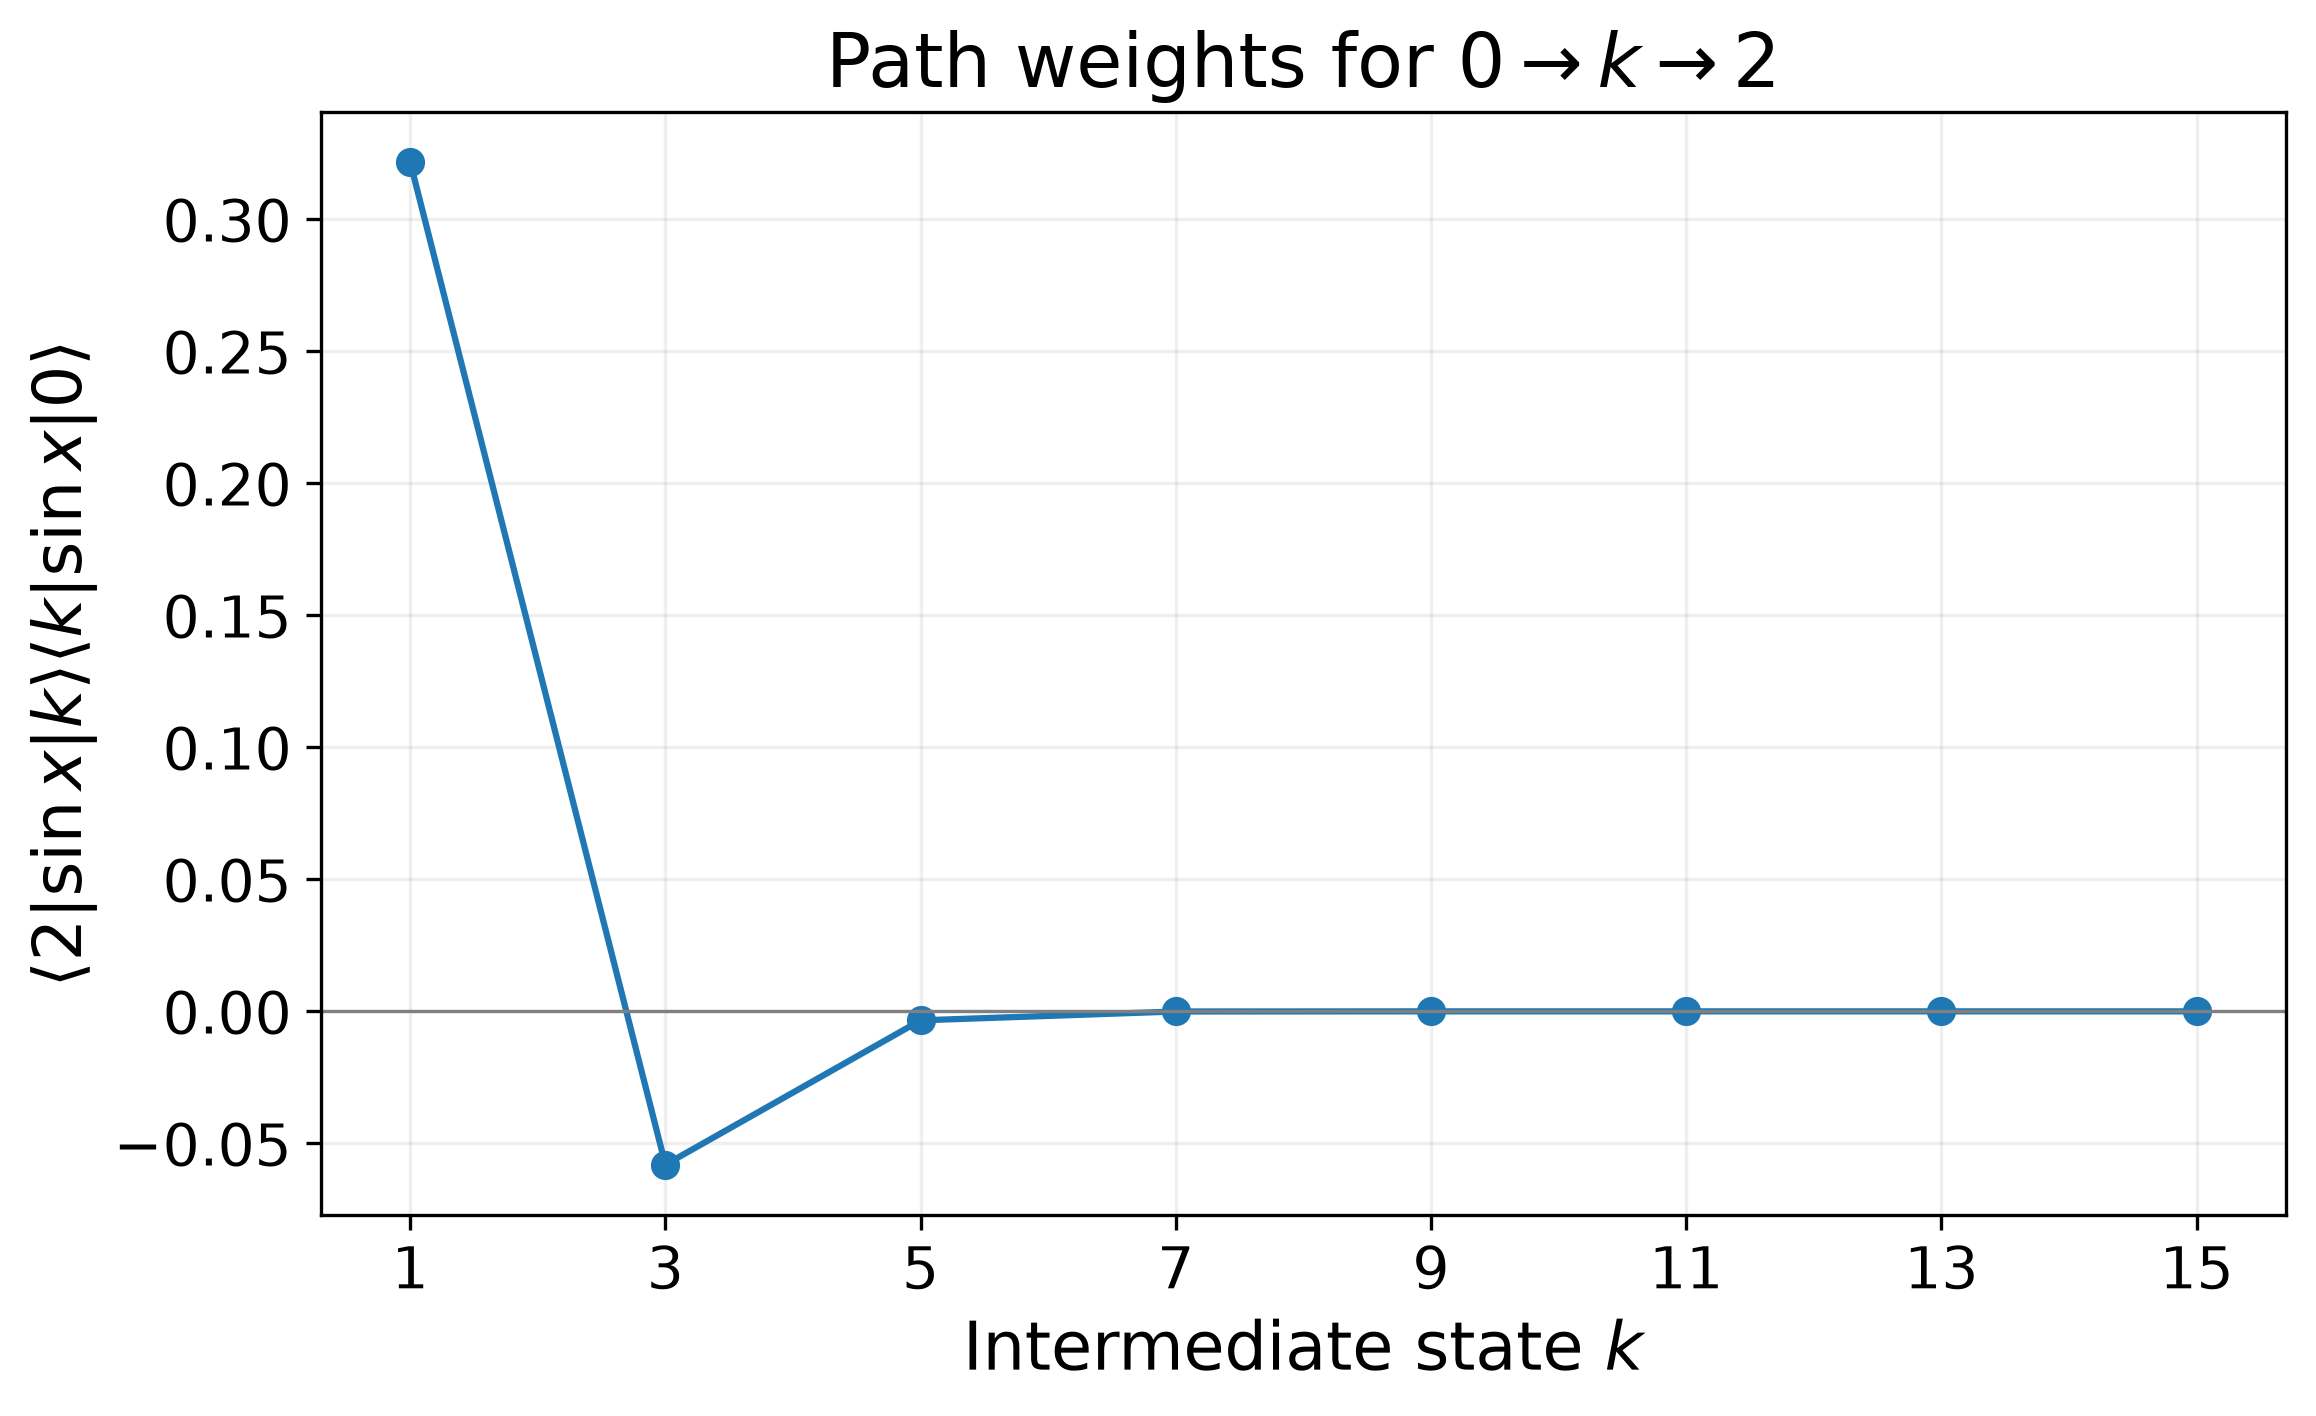

In [ ]:
from analytic import _sin_x
# Second-order 0 -> 2 goes through intermediate states k; sin x only couples odd k
k = np.arange(1, 16, 2)
plt.figure(figsize=(8, 5))
plt.plot(k, _sin_x(2, k) * _sin_x(k, 0), 'o-')
plt.axhline(0, color="gray", linewidth=0.8)
plt.xticks(k)
plt.xlabel(r"Intermediate state $k$")
plt.ylabel(r"$\langle 2|\sin x|k\rangle\langle k|\sin x|0\rangle$")
plt.title(r"Path weights for $0 \to k \to 2$")
plt.grid(alpha=0.2)

plt.tight_layout()

print(_sin_x(0,5)*_sin_x(5,4))